In [55]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,FightID,weapon_jedai,armour_jedai,weapon_calmtrooper,armour_calmtrooper,injuries,number_of_fights,force_level,accuracy_calmtrooper,fight_planet,weather_conditions,surprise_attack,moral_jedai,moral_calmtrooper,winner
0,640,Single Lightsaber,48.7%,Standard Blaster,79.2%,Jedai,151.4,28.1,75.0,Kamira,Storm,False,26.8,73.4,0
1,6876,Ancient Jedai Blade,73.8%,Heavy Blaster,66.9%,Both,67.4,58.0,59.1,Corsavant,Storm,True,53.9,64.7,0
2,7664,Ancient Jedai Blade,60.9%,Heavy Blaster,66.2%,Both,3.0,53.3,62.9,Tavooine,Sandstorm,False,51.0,57.5,0
3,4463,Double Lightsaber,80.3%,Experimental Weapon,37.2%,Calmtrooper,45.8,81.7,47.4,Kamira,Sandstorm,True,69.4,37.8,1
4,461,Single Lightsaber,54.9%,Standard Blaster,83.2%,Jedai,71.5,39.3,71.6,Kamira,Snow,True,52.4,77.1,0


In [56]:
subtask1 = len(df_test[(df_test.weather_conditions == "Snow") & (df_test.fight_planet == "Nabira")])
subtask2 = len(df_train[df_train.weapon_calmtrooper == "Experimental Weapon"])

def replace(val):
    if val == "Experimental Weapon":
        return "Double Blaster"
    return val

df_train.weapon_calmtrooper = df_train.weapon_calmtrooper.apply(replace)

df_subtasks = pd.DataFrame({
    "subtaskID": [1, 2],
    "datapointID": [1, 2],
    "answer": [subtask1, subtask2]
})

df_subtasks

,subtaskID,datapointID,answer
0,1,1,143
1,2,2,1646


In [57]:
df_train.columns

Index(['FightID', 'weapon_jedai', 'armour_jedai', 'weapon_calmtrooper',
       'armour_calmtrooper', 'injuries', 'number_of_fights', 'force_level',
       'accuracy_calmtrooper', 'fight_planet', 'weather_conditions',
       'surprise_attack', 'moral_jedai', 'moral_calmtrooper', 'winner'],
      dtype='object')

In [58]:
#simple preprocessing

df_train.armour_jedai = df_train.armour_jedai.apply(lambda val : float(str(val).split('%')[0]))
df_test.armour_jedai = df_test.armour_jedai.apply(lambda val : float(str(val).split('%')[0]))

df_train.armour_calmtrooper = df_train.armour_calmtrooper.apply(lambda val : float(str(val).split('%')[0]))
df_test.armour_calmtrooper = df_test.armour_calmtrooper.apply(lambda val : float(str(val).split('%')[0]))

cat_features = ['weapon_jedai', 'weapon_calmtrooper', 'injuries', 'fight_planet', 'weather_conditions']
from sklearn.preprocessing import TargetEncoder
enc = TargetEncoder()
df_train[cat_features] = enc.fit_transform(df_train[cat_features], df_train.winner)
df_test[cat_features] = enc.transform(df_test[cat_features])

df_train.head()

,FightID,weapon_jedai,armour_jedai,weapon_calmtrooper,armour_calmtrooper,injuries,number_of_fights,force_level,accuracy_calmtrooper,fight_planet,weather_conditions,surprise_attack,moral_jedai,moral_calmtrooper,winner
0,640,0.000000,48.7,0.000000,79.2,0.098355,151.4,28.1,75.0,0.428597,0.460141,False,26.8,73.4,0
1,6876,0.348354,73.8,0.348354,66.9,0.434560,67.4,58.0,59.1,0.428594,0.447910,True,53.9,64.7,0
2,7664,0.343434,60.9,0.343434,66.2,0.437263,3.0,53.3,62.9,0.455456,0.420267,False,51.0,57.5,0
3,4463,1.000000,80.3,1.000000,37.2,0.808564,45.8,81.7,47.4,0.438412,0.419884,True,69.4,37.8,1
4,461,0.000000,54.9,0.000000,83.2,0.103057,71.5,39.3,71.6,0.450818,0.440124,True,52.4,77.1,0


In [106]:
features = [col for col in df_test.columns if col != 'FightID']
target = "winner"

X = df_train[features]
y = df_train[target]

X_final = df_test[features]

X.head()

,weapon_jedai,armour_jedai,weapon_calmtrooper,armour_calmtrooper,injuries,number_of_fights,force_level,accuracy_calmtrooper,fight_planet,weather_conditions,surprise_attack,moral_jedai,moral_calmtrooper
0,0.000000,48.7,0.000000,79.2,0.098355,151.4,28.1,75.0,0.428597,0.460141,False,26.8,73.4
1,0.348354,73.8,0.348354,66.9,0.434560,67.4,58.0,59.1,0.428594,0.447910,True,53.9,64.7
2,0.343434,60.9,0.343434,66.2,0.437263,3.0,53.3,62.9,0.455456,0.420267,False,51.0,57.5
3,1.000000,80.3,1.000000,37.2,0.808564,45.8,81.7,47.4,0.438412,0.419884,True,69.4,37.8
4,0.000000,54.9,0.000000,83.2,0.103057,71.5,39.3,71.6,0.450818,0.440124,True,52.4,77.1


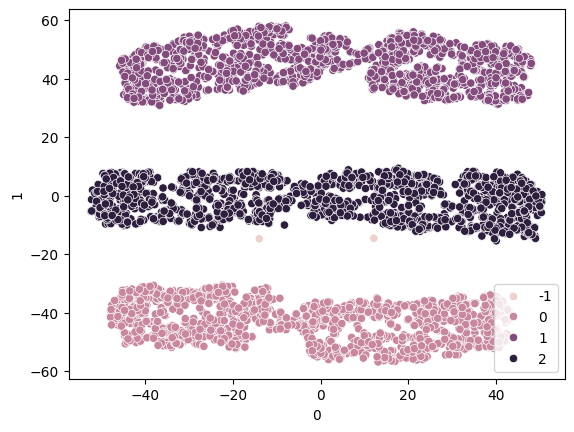

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN

pca = TSNE(n_components=2)
X_red = pd.DataFrame(pca.fit_transform(X_final))

cl = DBSCAN(eps=5)
labels = cl.fit_predict(X_red)

sns.scatterplot(x = X_red[0], y = X_red[1], hue=labels)
plt.show()

In [109]:
df_1 = pd.DataFrame({
    "subtaskID": 3,
    "datapointID": df_test.FightID,
    "answer": labels
})

df_1.answer = abs(df_1.answer)

df_1.head()

,subtaskID,datapointID,answer
0,3,1596,0
1,3,4432,1
2,3,486,0
3,3,6503,2
4,3,4650,1


In [110]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score

model = LinearSVC()

cross_val_score(model, X, y, cv=5, scoring='f1_macro').mean()

0.998579892177692

In [111]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [112]:
df_2 = pd.DataFrame({
    "subtaskID": 4,
    "datapointID": df_test.FightID,
    "answer": y_preds
})

df_2.head()

,subtaskID,datapointID,answer
0,4,1596,0
1,4,4432,1
2,4,486,0
3,4,6503,0
4,4,4650,1


In [113]:
submission = pd.concat([df_subtasks, df_1, df_2])

submission

,subtaskID,datapointID,answer
0,1,1,143
1,2,2,1646
0,3,1596,0
1,3,4432,1
2,3,486,0
...,...,...,...
3996,4,4843,1
3997,4,6117,1
3998,4,5810,1
3999,4,3589,1


In [114]:
submission.to_csv("submission.csv", index=False)